## Self-reflection topology demonstration

In this notebook we present the capabilities of the self-reflection multi-agent topology. In this setup, an agent provides an answer to a provided prompt and then provides feedback on its own output (self-reflection). To illustrate the capabilities of this agent topology we will load a sample dataset (*California Housing dataset*) and write a simple neural network to predict the median house value. The self-reflection feedback will then be used to to update the output of the agent. 

#### MAS setup

In [1]:
import sys
import os
import json
from pathlib import Path
from IPython.display import Markdown, display

# If the notebook lives in examples/, make sure src/ is importable
sys.path.insert(0, str(Path.cwd().parent / "src"))

from mas_topologies import TopologyAgent, PromptSet



**API setup:**

In [ ]:
os.environ["OPENAI_API_KEY"] = "..."
os.environ["ANTHROPIC_API_KEY"] = "..."

In [15]:
def build_client(provider="auto"):
    if provider in ("openai", "auto") and os.environ.get("OPENAI_API_KEY"):
        from autogen_ext.models.openai import OpenAIChatCompletionClient
        model = os.environ.get("OPENAI_MODEL", "gpt-4o-mini")
        client = OpenAIChatCompletionClient(model=model, api_key=os.environ["OPENAI_API_KEY"])
        return client, f"openai/{model}"

    if provider in ("anthropic", "auto") and os.environ.get("ANTHROPIC_API_KEY"):
        from autogen_ext.models.anthropic import AnthropicChatCompletionClient
        model = os.environ.get("ANTHROPIC_MODEL", "claude-haiku-4-5")
        client = AnthropicChatCompletionClient(model=model, api_key=os.environ["ANTHROPIC_API_KEY"])
        return client, f"anthropic/{model}"

    raise EnvironmentError(
        "No API key found. Export OPENAI_API_KEY or ANTHROPIC_API_KEY before running this notebook."
    )

MODEL_CLIENT, PROVIDER_LABEL = build_client("auto")
print(f"Provider : {PROVIDER_LABEL}")

Provider : openai/gpt-4o-mini


#### Agent prompt setup:

In [16]:
SYSTEM_PROMPT = """You are an expert PyTorch model architect.
For the California Housing regression task, return ONLY the neural network architecture.

Requirements:
- Do not load data
- Do not preprocess data
- Do not split datasets
- Do not define a training loop
- Do not evaluate or print metrics
- Do not include any dataset URLs

Return only:
- a PyTorch `nn.Module` class
- a `create_model(input_dim)` factory function
- a short architecture rationale if needed

The model should accept 8 numeric input features and output a single regression value."""

REFLECTION_PROMPT = """Review the model architecture above.
Check only the architecture itself:
- correct input/output shape
- regression output is a single scalar
- activations are appropriate
- dropout/regularization is reasonable
- no dataset loading, training, or evaluation code is present

If you find issues, produce a corrected architecture-only response.
If the architecture is correct, confirm it and do not add any training code."""

PROMPT_SET = PromptSet(
    system_message=SYSTEM_PROMPT,
    reflection_prompt=REFLECTION_PROMPT,
)

LOG_DIR = Path("logs")
LOG_DIR.mkdir(exist_ok=True)

HOUSING_CONTEXT = """California Housing regression task:
- Input: 8 numeric features
- Output: single scalar median house value
- Return ONLY the PyTorch model architecture
- Do NOT load data, preprocess data, split datasets, train, or evaluate
- Do NOT include hyperparameter recommendations"""

agent = TopologyAgent(
    model_client=MODEL_CLIENT,
    topology="self_reflection",
    prompts=PROMPT_SET,
    log_dir=LOG_DIR,
)

print("Self-reflection agent ready")
print(HOUSING_CONTEXT)

[TopologyAgent] Session log: logs/session_20260621_184252.jsonl
Self-reflection agent ready
California Housing regression task:
- Input: 8 numeric features
- Output: single scalar median house value
- Return ONLY the PyTorch model architecture
- Do NOT load data, preprocess data, split datasets, train, or evaluate
- Do NOT include hyperparameter recommendations


#### Dataset setup

In [5]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
import pandas as pd

# Load the dataset
housing = fetch_california_housing(as_frame=True)

# Convert to a DataFrame for easy inspection
df = housing.frame
print("Dataset shape:", df.shape)
print("Features:", housing.feature_names)
display(df.head())

# Separate features and target
X = df[housing.feature_names]
y = df["MedHouseVal"]

# Train / validation split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train shape: {X_train.shape}, Validation shape: {X_val.shape}")

Dataset shape: (20640, 9)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Train shape: (16512, 8), Validation shape: (4128, 8)


#### Running the MAS

In [17]:
result = await agent.run(
    HOUSING_CONTEXT,
    metadata={"task": "california_housing", "topology": "self_reflection"},
)

print(f"Rounds used: {result.rounds_used}")
print("-" * 80)
print(result.response_text)


[TopologyAgent] topology=self_reflection

--- Architect (round 1 - initial) ---
```python
import torch
import torch.nn as nn

class HousingRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super(HousingRegressionModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 16)
        self.fc4 = nn.Linear(16, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.relu(self.fc3(x))
        x = self.fc4(x)
        return x

def create_model(input_dim):
    return HousingRegressionModel(input_dim)
```

**Architecture Rationale:** 
The model consists of four fully connected layers with ReLU activations, which help capture non-linear relationships in the data. Dropout is added to prevent overfitting. The archit

**Run statistics:**

In [18]:
print("\n=== Agent run statistics: ===\n")
print("Rounds used:", result.rounds_used)
print("Total messages:", len(result.messages))
print("Final response length:", len(result.response_text))


=== Agent run statistics: ===

Rounds used: 4
Total messages: 7
Final response length: 1758


**Printing the generated code:**

In [19]:
import re

# Extract the final Python code block from the agent's response
code_pattern = r"```python\n(.*?)```"
code_matches = re.findall(code_pattern, result.response_text, re.DOTALL)

if code_matches:
    final_code = code_matches[0].strip()
    print("=== Final Generated Code ===\n")
    print(final_code)
else:
    print("No Python code block found in the response")

=== Final Generated Code ===

import torch
import torch.nn as nn

class HousingRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super(HousingRegressionModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 16)
        self.fc4 = nn.Linear(16, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.relu(self.fc3(x))
        x = self.fc4(x)
        return x

def create_model(input_dim):
    return HousingRegressionModel(input_dim)


#### Running the generated code: 

**Execute the generated code to define the model class:**

In [20]:
# Execute the generated code to define the model class
exec(final_code)

# Verify the model was created
print("\n=== Model created successfully ===")
model = create_model(input_dim=X_train.shape[1])
print(model)
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters())}")


=== Model created successfully ===
HousingRegressionModel(
  (fc1): Linear(in_features=8, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=16, bias=True)
  (fc4): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
)

Total parameters: 3201


**Evaluating the trained model:**

In [ ]:
### Improved training: 

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
import numpy as np

print("X_train shape:", X_train.shape)
print("Using input_dim:", X_train.shape[1])

# 1) Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# 2) Convert to tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)

# 3) DataLoaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)

# 4) Model, loss, optimizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = create_model(input_dim=X_train.shape[1]).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-5,             # regularization
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=10,
    min_lr=1e-6,
    verbose=True,
)

print(f"Training on: {device}")
print(f"Training samples: {len(train_dataset)}, Validation samples: {len(val_dataset)}")

# 5) Training loop
num_epochs = 200
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * X_batch.size(0)

    train_loss /= len(train_dataset)
    train_losses.append(train_loss)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * X_batch.size(0)

    val_loss /= len(val_dataset)
    val_losses.append(val_loss)

    scheduler.step(val_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Train Loss: {train_loss:.4f} "
            f"Val Loss: {val_loss:.4f} "
            f"LR: {optimizer.param_groups[0]['lr']:.6f}"
        )

print("\n=== Training Complete ===")

X_train shape: (16512, 8)
Using input_dim: 8
Training on: cpu
Training samples: 16512, Validation samples: 4128


/home/axt807/miniconda3/envs/autogen_gpu/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


Epoch [1/200] Train Loss: 1.8502 Val Loss: 0.6506 LR: 0.001000
Epoch [10/200] Train Loss: 0.4003 Val Loss: 0.3450 LR: 0.001000
Epoch [20/200] Train Loss: 0.3533 Val Loss: 0.3170 LR: 0.001000
Epoch [30/200] Train Loss: 0.3245 Val Loss: 0.2961 LR: 0.001000
Epoch [40/200] Train Loss: 0.3075 Val Loss: 0.2858 LR: 0.001000
Epoch [50/200] Train Loss: 0.3011 Val Loss: 0.2809 LR: 0.001000
Epoch [60/200] Train Loss: 0.2939 Val Loss: 0.2812 LR: 0.001000
Epoch [70/200] Train Loss: 0.2904 Val Loss: 0.2754 LR: 0.001000
Epoch [80/200] Train Loss: 0.2857 Val Loss: 0.2778 LR: 0.001000
Epoch [90/200] Train Loss: 0.2825 Val Loss: 0.2740 LR: 0.001000
Epoch [100/200] Train Loss: 0.2830 Val Loss: 0.2707 LR: 0.001000
Epoch [110/200] Train Loss: 0.2794 Val Loss: 0.2711 LR: 0.001000
Epoch [120/200] Train Loss: 0.2742 Val Loss: 0.2701 LR: 0.001000
Epoch [130/200] Train Loss: 0.2687 Val Loss: 0.2669 LR: 0.000500
Epoch [140/200] Train Loss: 0.2669 Val Loss: 0.2635 LR: 0.000250
Epoch [150/200] Train Loss: 0.2634 V


=== Validation Set Performance ===
MSE:  0.2623
RMSE: 0.5122
MAE:  0.3429
R²:   0.7998


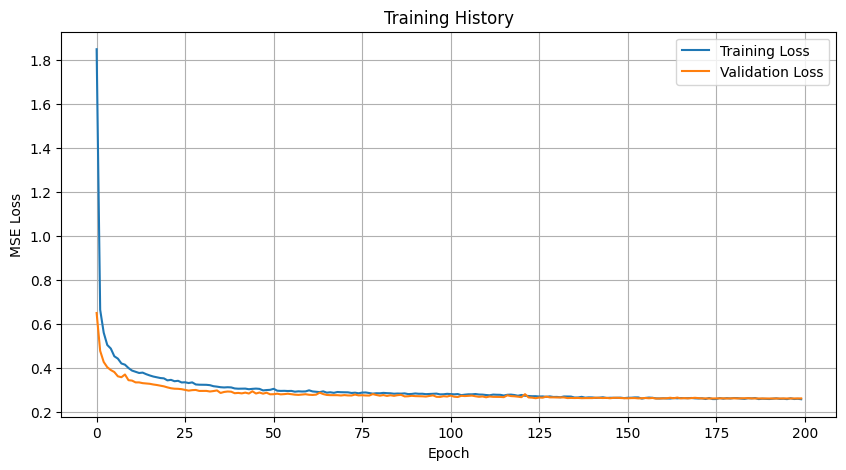

In [26]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Final evaluation
model.eval()
with torch.no_grad():
    # Get predictions on validation set
    y_val_pred = model(X_val_tensor.to(device)).cpu().numpy()
    y_val_actual = y_val_tensor.numpy()
    
    # Compute metrics
    mse = mean_squared_error(y_val_actual, y_val_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_val_actual, y_val_pred)
    r2 = r2_score(y_val_actual, y_val_pred)

print("\n=== Validation Set Performance ===")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"R²:   {r2:.4f}")

# Plot training history
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training History')
plt.legend()
plt.grid(True)
plt.show()